# Part 1: Action Chunking with Direct MSE Regression

PushT with state observations $o_t\in\mathbb R^5$ (pusher x, y; T x, y, angle), actions $a_t\in\mathbb R^2$
(pusher **target position**), chunks $A_t\in\mathbb R^{K\times 2}$ with $K=8$.

Built on the UC Berkeley CS 185/285 Spring 2026 HW1 starter code
(`hw1_imitation/data.py`, `model.py`, `train.py`, `evaluation.py`). The adapted copies live in `pusht_ac/`;
each module's docstring lists what was kept and what was changed.

## 1. Setup

In [1]:
import json, time, platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage, display

from pusht_ac.data import (Normalizer, PushtChunkDataset, download_pusht, load_pusht_zarr,
                           split_episodes, episode_bounds, build_valid_indices)
from pusht_ac.model import build_policy, save_policy, load_policy
from pusht_ac.train import train_policy
from pusht_ac.evaluation import VAL_SEEDS, TEST_SEEDS, COLLECT_SEEDS, evaluate, summarize, rollout, save_gif
from pusht_ac import viz
from pusht_ac.viz import PAL

torch.set_num_threads(4)
RES, CKPT = Path('results_part1'), Path('checkpoints')
RES.mkdir(exist_ok=True); CKPT.mkdir(exist_ok=True)
RETRAIN = not (CKPT / 'mse_policy.pt').exists()

CFG = dict(chunk_size=8, hidden_dims=(256, 256, 256), activation='ReLU', batch_size=128, lr=3e-4,
           optimizer='Adam', steps=150_000, eval_every=5_000, split_seed=0, val_fraction=0.2,
           train_seed=0, val_reset_seeds='0-49', test_reset_seeds='1000-1099',
           collection_reset_seeds='2000-2024 (Part 3)', test_policy_seed='reset_seed (unused by MSE)',
           checkpoint_selection='max mean validation-rollout score over reset seeds 0-49; ties -> lower val loss')
versions = dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__,
                cpu=platform.processor(), torch_threads=torch.get_num_threads())
json.dump({**CFG, **versions}, open(RES / 'config.json', 'w'), indent=2)
print(json.dumps(versions, indent=1))

{
 "python": "3.12.10",
 "torch": "2.15.0+cpu",
 "numpy": "2.5.5",
 "cpu": "Intel64 Family 6 Model 198 Stepping 2, GenuineIntel",
 "torch_threads": 4
}


## 2. Task 1: Prepare and inspect the demonstrations

The 206 demonstrations are split **by complete episode** (80 / 20, seed 0). Normalization statistics are
fitted on the training episodes only and saved once; Parts 2 and 3 load the same file.

In [2]:
states, actions, episode_ends = load_pusht_zarr(download_pusht(Path('data')))
train_eps, val_eps = split_episodes(len(episode_ends), CFG['val_fraction'], CFG['split_seed'])
normalizer = Normalizer.from_episodes(states, actions, episode_ends, train_eps)
normalizer.save(CKPT / 'normalizer.json')
json.dump({'split_seed': CFG['split_seed'], 'train_episodes': train_eps.tolist(), 'val_episodes': val_eps.tolist()},
          open(CKPT / 'split.json', 'w'))

K = CFG['chunk_size']
train_ds = PushtChunkDataset(states, actions, episode_ends, K, normalizer, train_eps)
val_ds = PushtChunkDataset(states, actions, episode_ends, K, normalizer, val_eps)
lengths = np.diff(np.concatenate([[0], episode_ends]))

summary = {
    'episodes_total': len(episode_ends), 'episodes_train': len(train_eps), 'episodes_val': len(val_eps),
    'timesteps_total': len(states), 'timesteps_train': int(lengths[train_eps].sum()), 'timesteps_val': int(lengths[val_eps].sum()),
    'episode_length_min/median/max': [int(lengths.min()), int(np.median(lengths)), int(lengths.max())],
    'chunks_train': len(train_ds), 'chunks_val': len(val_ds),
    'obs_tensor_train': list(train_ds.obs.shape), 'chunk_tensor_train': list(train_ds.chunks.shape),
    'obs_tensor_val': list(val_ds.obs.shape), 'chunk_tensor_val': list(val_ds.chunks.shape),
    'windows_that_would_cross_a_boundary': int(len(states) - K + 1 - len(build_valid_indices(episode_ends, K))),
}
json.dump(summary, open(RES / 'data_summary.json', 'w'), indent=2)
pd.Series(summary).to_frame('value')

,value
episodes_total,206
episodes_train,165
episodes_val,41
timesteps_total,25650
timesteps_train,20684
timesteps_val,4966
episode_length_min/median/max,"[49, 122, 246]"
chunks_train,19529
chunks_val,4679
obs_tensor_train,"[19529, 5]"


In [3]:
print('normalizer (train episodes only)')
print(pd.DataFrame({'state_mean': normalizer.state_mean, 'state_std': normalizer.state_std},
                   index=['agent_x', 'agent_y', 'block_x', 'block_y', 'block_angle']).round(3))
print(pd.DataFrame({'action_mean': normalizer.action_mean, 'action_std': normalizer.action_std},
                   index=['target_x', 'target_y']).round(3))
print('normalized train chunks: mean', train_ds.chunks.mean().item().__round__(3), ' std', train_ds.chunks.std().item().__round__(3))

normalizer (train episodes only)
             state_mean   state_std
agent_x      228.507004  101.551003
agent_y      289.537994   96.662003
block_x      246.578003   64.179001
block_y      269.208008   64.906998
block_angle    1.821000    1.805000
          action_mean  action_std
target_x   227.804001  101.331001
target_y   290.269989   96.185997
normalized train chunks: mean 0.001  std 1.005


### One demonstration
Left: initial scene with the pusher path coloured by time and the T's final pose (dashed). The green T is the
fixed target (x = 256, y = 256, angle = π/4). Right: pusher position and commanded action over time.

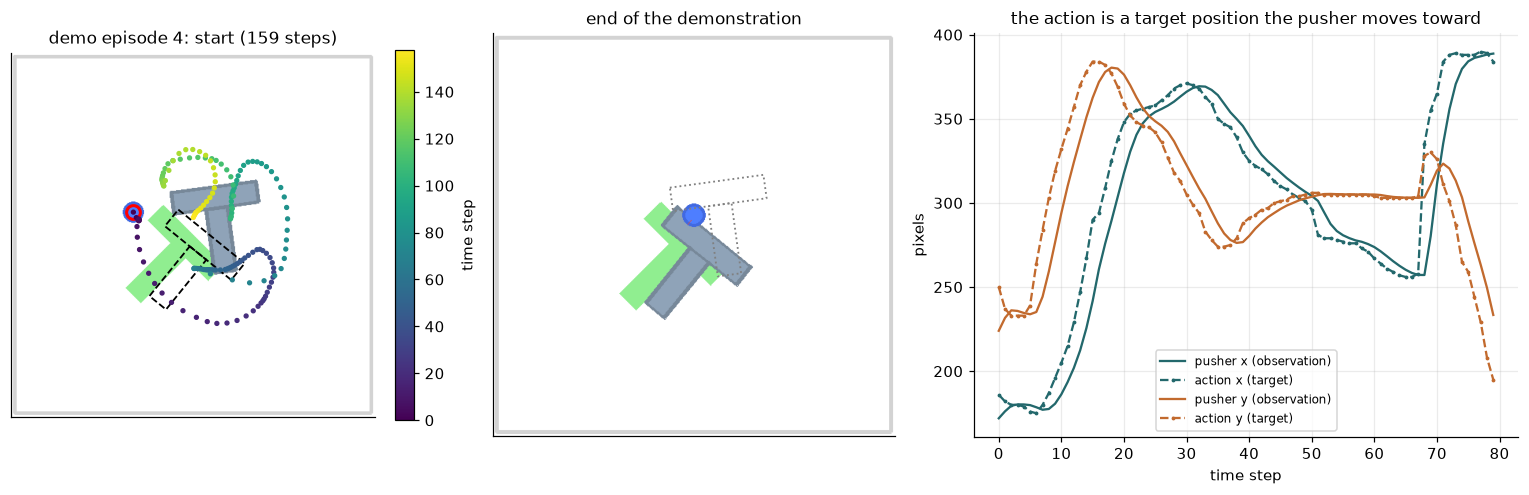

mean |a_t - pusher_(t+1)| = 11.9 px   vs   |a_t - pusher_t| = 19.8 px


In [4]:
ep = int(train_eps[3])
s0, s1 = episode_bounds(episode_ends, ep)
S, A = states[s0:s1], actions[s0:s1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1, 1.35]})
viz.show_scene(axes[0], S[0], title=f'demo episode {ep}: start ({s1 - s0} steps)')
sc = axes[0].scatter(S[:, 0], S[:, 1], c=np.arange(len(S)), cmap='viridis', s=6, zorder=3)
viz.draw_polys(axes[0], viz.block_polygons(S[-1]), color='k', ls='--', lw=1.2)
axes[0].plot(*S[0, :2], 'o', ms=9, mfc='none', mec='red', mew=2)
plt.colorbar(sc, ax=axes[0], fraction=0.046, label='time step')
viz.show_scene(axes[1], S[-1], title='end of the demonstration')
viz.draw_polys(axes[1], viz.block_polygons(S[0]), color='gray', ls=':', lw=1.2)
n = min(80, len(S))
for j, (lab, c) in enumerate([('x', PAL['flow']), ('y', PAL['mse'])]):
    axes[2].plot(S[:n, j], color=c, label=f'pusher {lab} (observation)')
    axes[2].plot(A[:n, j], color=c, ls='--', marker='.', ms=3, label=f'action {lab} (target)')
axes[2].set_xlabel('time step'); axes[2].set_ylabel('pixels'); axes[2].legend(fontsize=8)
axes[2].set_title('the action is a target position the pusher moves toward')
plt.tight_layout(); plt.savefig(RES / 'demo_episode.png', bbox_inches='tight'); plt.show()

lead = np.linalg.norm(A[:-1] - S[1:, :2], axis=1).mean(), np.linalg.norm(A[:-1] - S[:-1, :2], axis=1).mean()
print(f'mean |a_t - pusher_(t+1)| = {lead[0]:.1f} px   vs   |a_t - pusher_t| = {lead[1]:.1f} px')

### Why chunks must not cross an episode boundary
A window that crosses a boundary glues the end of one demonstration to the start of an unrelated one, with a
different T pose. The jump between consecutive actions at a boundary is far larger than any jump inside an episode:

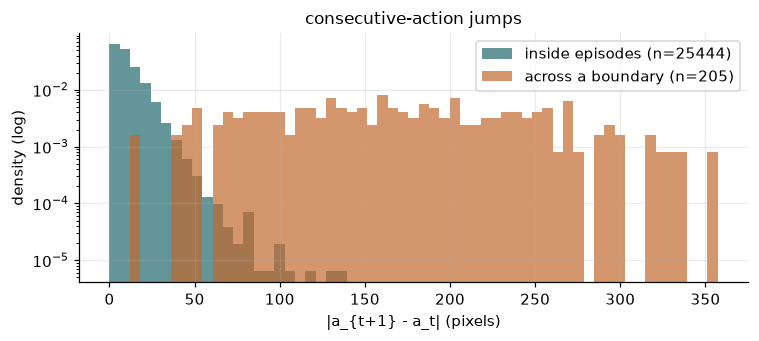

median jump inside: 8.1 px,  across boundaries: 164.3 px


In [5]:
within = np.concatenate([np.linalg.norm(np.diff(actions[a:b], axis=0), axis=1)
                         for a, b in (episode_bounds(episode_ends, e) for e in range(len(episode_ends)))])
across = np.linalg.norm(actions[episode_ends[:-1]] - actions[episode_ends[:-1] - 1], axis=1)
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, max(within.max(), across.max()), 60)
ax.hist(within, bins=bins, density=True, alpha=0.7, color=PAL['flow'], label=f'inside episodes (n={len(within)})')
ax.hist(across, bins=bins, density=True, alpha=0.7, color=PAL['mse'], label=f'across a boundary (n={len(across)})')
ax.set_yscale('log'); ax.set_xlabel('|a_{t+1} - a_t| (pixels)'); ax.set_ylabel('density (log)'); ax.legend()
ax.set_title('consecutive-action jumps'); plt.tight_layout(); plt.savefig(RES / 'boundary_jumps.png', bbox_inches='tight'); plt.show()
print(f'median jump inside: {np.median(within):.1f} px,  across boundaries: {np.median(across):.1f} px')

## 3. Task 2: Train the MSE policy

$f_\theta(o)\in\mathbb R^{K\times 2}$: an MLP 5 → 256 → 256 → 256 → 16 (ReLU), reshaped to 8 actions, trained on
$\frac{1}{2K}\|f_\theta(o)-A\|_F^2$ with Adam (lr 3e-4, batch 128) for 150k steps. Every 5k steps the policy is
rolled out on validation reset seeds 0–49; the checkpoint with the best validation score is kept.

In [6]:
torch.manual_seed(CFG['train_seed'])
if RETRAIN:
    mse = build_policy('mse', chunk_size=K, hidden_dims=CFG['hidden_dims'])
    mse, log, evals, info, mse_last = train_policy(mse, train_ds, val_ds, normalizer, steps=CFG['steps'],
                                                    batch_size=CFG['batch_size'], lr=CFG['lr'],
                                                    eval_every=CFG['eval_every'], seed=CFG['train_seed'])
    save_policy(mse, CKPT / 'mse_policy.pt', **info, **{k: str(v) for k, v in CFG.items()})
    log.to_csv(RES / 'mse_train_log.csv', index=False); evals.to_csv(RES / 'mse_val_rollouts.csv', index=False)
    json.dump(info, open(RES / 'mse_train_info.json', 'w'), indent=2)
mse = load_policy(CKPT / 'mse_policy.pt')
log, evals = pd.read_csv(RES / 'mse_train_log.csv'), pd.read_csv(RES / 'mse_val_rollouts.csv')
info = json.load(open(RES / 'mse_train_info.json'))
print(f"parameters: {sum(p.numel() for p in mse.parameters()):,}")
print(json.dumps(info, indent=1))

parameters: 137,232
{
 "best_step": 115000,
 "train_time_s": 271.6983896039019,
 "val_rollout_time_s": 136.10416980000446,
 "wall_time_s": 412.40814020000107
}


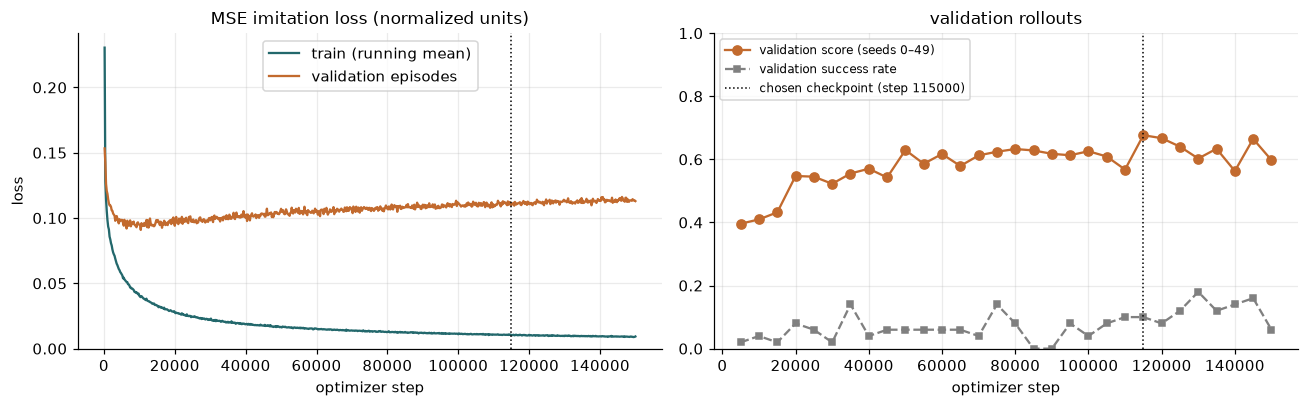

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
viz.plot_losses(axes[0], log, 'MSE imitation loss (normalized units)', 'loss')
axes[0].axvline(info['best_step'], color='k', ls=':', lw=1); axes[0].set_ylim(0, None)
axes[1].plot(evals.step, evals.val_score, 'o-', color=PAL['mse'], label='validation score (seeds 0–49)')
axes[1].plot(evals.step, evals.val_success, 's--', color='gray', ms=4, label='validation success rate')
axes[1].axvline(info['best_step'], color='k', ls=':', lw=1, label=f"chosen checkpoint (step {info['best_step']})")
axes[1].set_xlabel('optimizer step'); axes[1].set_ylim(0, 1); axes[1].legend(fontsize=8)
axes[1].set_title('validation rollouts')
plt.tight_layout(); plt.savefig(RES / 'mse_losses.png', bbox_inches='tight'); plt.show()

### Squared error pulls toward the conditional mean

For a fixed $o$, $\mathbb E_{A\mid o}\|f-A\|^2$ is minimized by $f=\mathbb E[A\mid o]$. If two demonstrators
went around the T in opposite directions from nearly the same state, the minimizer sits between them.
Below, an observation is picked automatically from the training set: among 3000 random training observations,
the one whose 12 nearest neighbours (normalized observation space, other episodes only) have the most spread-out
expert chunks. The neighbours' chunks are drawn in gray, the MSE prediction in orange.

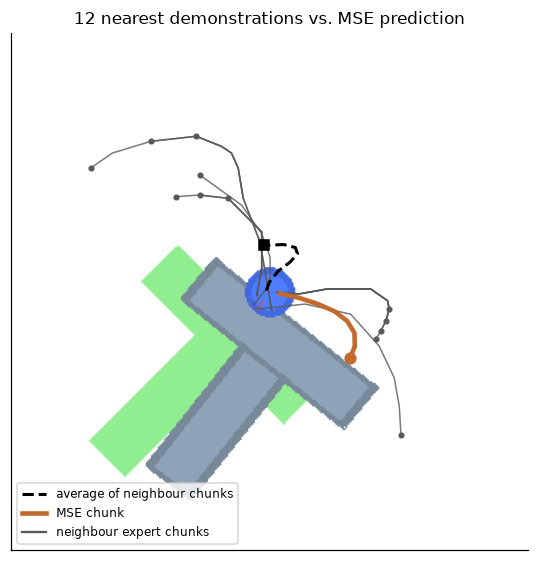

MSE chunk distance to neighbour mean: 46.1 px; to the closest neighbour chunk: 17.6 px


In [8]:
ep_of = np.searchsorted(episode_ends, train_ds.indices, side='right')
obs_n = train_ds.obs.numpy()
rng = np.random.default_rng(0)
cand = rng.choice(len(obs_n), 3000, replace=False)
raw_chunks = actions[train_ds.indices[:, None] + np.arange(K)]
best = None
for i in cand:
    d = np.linalg.norm(obs_n - obs_n[i], axis=1)
    d[ep_of == ep_of[i]] = np.inf
    nn = np.argsort(d)[:12]
    disp = raw_chunks[nn, -1] - states[train_ds.indices[nn], :2]      # where each chunk ends, rel. to pusher
    spread = np.linalg.norm(disp - disp.mean(0), axis=1).mean() / (d[nn].mean() + 0.05)
    if best is None or spread > best[0]:
        best = (spread, int(i), nn)
_, qi, nn = best
json.dump({'train_chunk_index': qi, 'neighbors': nn.tolist()}, open(RES / 'multimodal_obs.json', 'w'))
q_state = states[train_ds.indices[qi]]
with torch.no_grad():
    pred = normalizer.denormalize_action(mse(train_ds.obs[qi:qi + 1])[0].numpy())

fig, ax = plt.subplots(figsize=(5.2, 5.2))
viz.show_scene(ax, q_state, title='12 nearest demonstrations vs. MSE prediction')
for j in nn:
    ax.plot(*raw_chunks[j].T, '-', color='0.35', lw=1, alpha=0.8)
    ax.plot(*raw_chunks[j, -1], 'o', color='0.35', ms=3)
mean_chunk = raw_chunks[nn].mean(0)
ax.plot(*mean_chunk.T, '--', color='k', lw=2, label='average of neighbour chunks')
ax.plot(*mean_chunk[-1], 's', color='k', ms=6)
ax.plot(*pred.T, '-', color=PAL['mse'], lw=3, label='MSE chunk')
ax.plot(*pred[-1], 'o', color=PAL['mse'], ms=7)
ax.plot([], [], color='0.35', label='neighbour expert chunks')
ax.legend(loc='lower left', fontsize=8)
pad = 70; c = q_state[:2]
ax.set_xlim(c[0] - 2.2 * pad, c[0] + 2.2 * pad); ax.set_ylim(c[1] + 2.2 * pad, c[1] - 2.2 * pad)
plt.tight_layout(); plt.savefig(RES / 'conditional_mean.png', bbox_inches='tight'); plt.show()
mean_chunk = raw_chunks[nn].mean(0)
print(f'MSE chunk distance to neighbour mean: {np.linalg.norm(pred - mean_chunk, axis=1).mean():.1f} px; '
      f'to the closest neighbour chunk: {min(np.linalg.norm(pred - raw_chunks[j], axis=1).mean() for j in nn):.1f} px')

## 4. Task 3: Evaluate the learned behavior

Final test set: reset seeds 1000–1099 (100 episodes, never used for any choice). The policy is queried, the
chunk is denormalized and clipped to [0, 512]², its 8 actions are executed, and the policy is queried again.
The episode ends immediately on termination (success) or truncation (300 steps).

In [9]:
test_df, test_eps = evaluate(mse, normalizer, TEST_SEEDS)
test_df.to_csv(RES / 'mse_test_episodes.csv', index=False)
s = summarize(test_df)
n_queries = int(np.ceil(test_df.length / K).sum())
s.update(policy_time_s=test_df.policy_time_s.sum(), ms_per_query=1000 * test_df.policy_time_s.sum() / n_queries,
         env_steps=int(test_df.length.sum()))
json.dump(s, open(RES / 'mse_test_summary.json', 'w'), indent=2)
pd.Series(s).round(4).to_frame('MSE policy, test seeds 1000-1099')

,"MSE policy, test seeds 1000-1099"
score_mean,0.5749
score_std,0.3971
success_rate,0.1100
mean_length,286.0800
rollout_time_s,8.5091
n,100.0000
policy_time_s,0.5826
ms_per_query,0.1607
env_steps,28608.0000


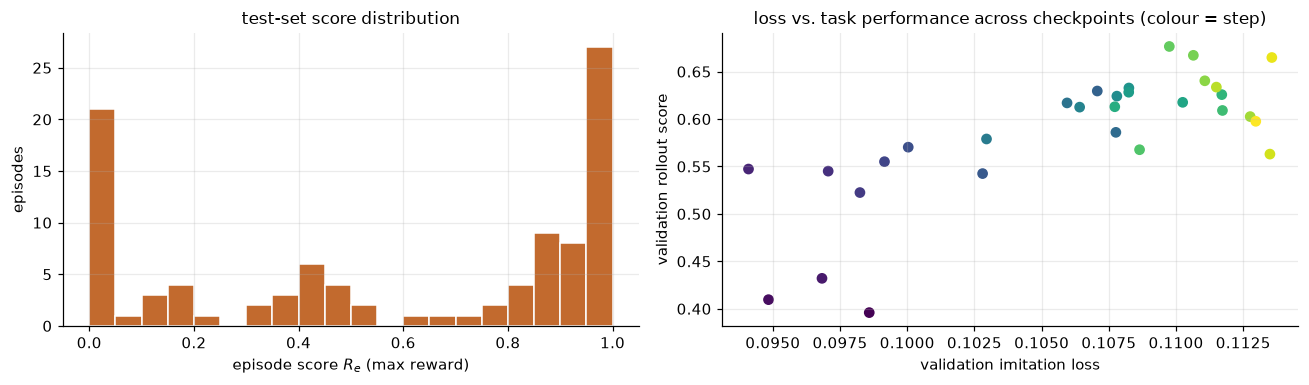

Spearman corr(val loss, val score) across checkpoints: 0.657


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(test_df.max_reward, bins=np.linspace(0, 1, 21), color=PAL['mse'], edgecolor='white')
axes[0].set_xlabel('episode score $R_e$ (max reward)'); axes[0].set_ylabel('episodes'); axes[0].set_title('test-set score distribution')
axes[1].scatter(evals.val_loss, evals.val_score, c=evals.step, cmap='viridis')
axes[1].set_xlabel('validation imitation loss'); axes[1].set_ylabel('validation rollout score')
axes[1].set_title('loss vs. task performance across checkpoints (colour = step)')
plt.tight_layout(); plt.savefig(RES / 'mse_test_hist.png', bbox_inches='tight'); plt.show()
print('Spearman corr(val loss, val score) across checkpoints:', round(evals[['val_loss', 'val_score']].corr('spearman').iloc[0, 1], 3))

### Strongest and weakest test rollouts (and the shared illustration seed 1100)

best     reset seed 1005: score 1.000, success True, length 208


worst    reset seed 1096: score 0.000, success False, length 300


seed1100 reset seed 1100: score 0.000, success False, length 300


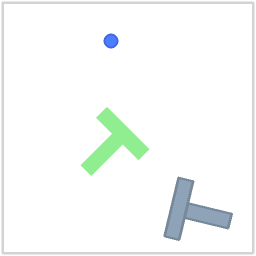

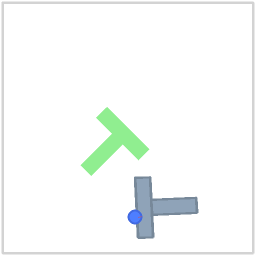

In [11]:
order = test_df.sort_values(['success', 'max_reward'], ascending=False)
picks = {'best': int(order.reset_seed.iloc[0]), 'worst': int(order.reset_seed.iloc[-1]), 'seed1100': 1100}
for name, seed in picks.items():
    e = rollout(mse, normalizer, seed, seed, render=True)
    save_gif(e.frames, RES / f'mse_{name}.gif')
    print(f'{name:8s} reset seed {seed}: score {e.max_reward:.3f}, success {e.success}, length {e.length}')
json.dump(picks, open(RES / 'gif_seeds.json', 'w'))
display(ShowImage(filename=str(RES / 'mse_best.gif')), ShowImage(filename=str(RES / 'mse_worst.gif')))

## 5. Findings (Part 1)

**Data.** 206 demonstrations → 165 training / 41 validation episodes (episode-level split, seed 0); 19,529 / 4,679
valid chunks. Training tensors: observations `[19529, 5]`, chunks `[19529, 8, 2]`. With $K=8$ each episode loses its
last 7 start indices; a naive sliding window over the concatenated data would have produced 1,435 windows that cross
an episode boundary.

**What an action is.** $a_t$ is the pixel position the pusher is driven toward, not a force or a velocity. The
pusher lags it: $|a_t-p_{t+1}|$ averages 11.9 px against 19.8 px for $|a_t-p_t|$. So a chunk of 8 actions is a short
path of way-points, about 0.8 s at the 10 Hz control rate.

**Why chunks stay inside an episode.** Consecutive actions inside an episode move a median of 8 px. Across a boundary
the median jump is 164 px, and the next actions belong to a different T pose. A crossing window would teach the network
to jump to an unrelated start position for reasons the observation cannot show.

**Conditional mean.** For one observation, $\arg\min_f \mathbb E\|f-A\|^2=\mathbb E[A\mid o]$. When demonstrators
went around the T in different directions from similar states, that average lies between the modes and may not be a
valid push. This is a pull, not a guarantee. In the neighbourhood picked above, the 3 × 256 network trained to step 115k
predicts a chunk 17.6 px from the closest expert chunk and 46 px from the neighbour average. With enough capacity, the
network separates nearby observations instead of averaging them (training loss 0.010 against validation loss 0.110 is
a sign of this memorization). Whether averaging hurts therefore has to be measured in the simulator.

**Simulator results** (test reset seeds 1000–1099, never used for any choice): score **0.575 ± 0.397**
(mean ± std of $R_e$), success **11 / 100**. Rolling out 100 episodes took 7.2 s; one policy query takes 0.13 ms;
training took 272 s on a CPU.

**Loss and task performance are different measurements.** Validation imitation loss is lowest near 10k steps (0.091)
and then rises, while the validation rollout score keeps improving to ≈ 0.68 at 115k steps. Across checkpoints the
Spearman correlation between validation loss and validation score is **+0.66**: higher loss went with *better*
control. The loss is an open-loop, one-step average over expert states, and every coordinate counts equally. The score
is closed-loop: small errors move the system to states the expert never visited, they compound over about 37 queries,
and the outcome depends on a few contacts where a 10-pixel error decides whether the T turns.

**Observed failures** (GIFs above). On seed 1096 the T starts near the bottom-right wall, and the pusher dithers against
one corner of it for the whole episode without turning it. On illustration seed 1100 the predicted chunk points outside
the arena. After clipping, the pusher is pinned against the right wall for 300 steps, a closed-loop extrapolation failure
on an unfamiliar start. The best episode (seed 1005) is a clean multi-contact push that reaches 95% coverage in 208
steps. MSE regression is not hopeless here: 11 successes, 35 episodes at or above 0.9 and a median score of 0.74 show it often works. Its
failures are mostly getting stuck, not averaged motions that cancel out.